# Machine Learning — Deliverable 1 (versão corrigida)
## Identificação de funcionários com alta utilização de IA

**DAMA Intelligence** · Ana Luiza Proença, Gustavo Gomes, Kaique Lira e Ricardo Matteo · Ciência de Dados e Negócios, ESPM, 4º semestre, 2026

Versão corrigida de `main.ipynb`. O original foi mantido para comparação. A pergunta é a mesma: **quais características dos funcionários e das empresas estão ligadas a uma alta utilização de IA?** Na revisão, apareceram os problemas abaixo.

| Problema no original | Efeito | Correção |
|---|---|---|
| O alvo somava as requisições dos 14 meses | Quem foi contratado depois teve menos meses para acumular, então o alvo misturava intensidade com **tempo de exposição** | Alvo por **mês de exposição**: requisições ÷ meses entre a contratação (ou jun/2025) e jul/2026 |
| `tenure_days` sem padronização na regressão logística | Coeficientes em escalas diferentes, não comparáveis entre si | `StandardScaler` dentro de um `Pipeline` |
| Divisão treino/teste sem estratificação, e repetida em duas células | A proporção de alto uso podia variar entre treino e teste | `stratify=y` numa única divisão |
| Uma única divisão para avaliar | Resultado dependente da sorte da divisão | Validação cruzada estratificada repetida (5 dobras × 3) |
| Só regressão logística, sem baseline | Não dá para saber se o modelo é bom | Baseline da classe majoritária, regressão logística, Random Forest e gradient boosting |
| Só acurácia e relatório de classificação | Com 11% de positivos, a acurácia engana | ROC-AUC, PR-AUC, precisão, recall e F1 |
| Cargo com 75 categorias em one-hot | Muitas colunas com pouquíssimos exemplos | `min_frequency=10` agrupa os cargos raros |
| O caminho dos dados não batia com o diretório impresso | O notebook só rodava na máquina de quem o criou | Caminho relativo à pasta do repositório |

## 1. Configuração e dados

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, average_precision_score, classification_report, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
DADOS = Path('Data/csv')
SEED = 42
AZUL, LARANJA, CINZA = '#2a78d6', '#eb6834', '#8f8e89'
TINTA2, GRADE, FUNDO = '#52514e', '#e4e3df', '#fcfcfb'
plt.rcParams.update({'figure.facecolor': FUNDO, 'axes.facecolor': FUNDO, 'axes.edgecolor': GRADE, 'axes.labelcolor': TINTA2,
                     'xtick.color': TINTA2, 'ytick.color': TINTA2, 'axes.grid': True, 'grid.color': GRADE,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.titleweight': 'bold', 'legend.frameon': False})

employees = pd.read_csv(DADOS / 'employees.csv')
usage = pd.read_csv(DADOS / 'ai_usage_logs.csv', usecols=['usage_id', 'employee_id', 'timestamp', 'request_count'])
departments = pd.read_csv(DADOS / 'departments.csv')
companies = pd.read_csv(DADOS / 'companies.csv')
for nome, df in [('employees', employees), ('ai_usage_logs', usage), ('departments', departments), ('companies', companies)]:
    print(f'{nome:15s} {df.shape} | nulos: {int(df.isna().sum().sum())} | duplicadas: {int(df.duplicated().sum())}')

employees       (2356, 8) | nulos: 45 | duplicadas: 0


ai_usage_logs   (269515, 4) | nulos: 0 | duplicadas: 0
departments     (161, 3) | nulos: 0 | duplicadas: 0
companies       (18, 5) | nulos: 0 | duplicadas: 0


## 2. Alvo corrigido: alta utilização por mês de exposição

A exposição de cada funcionário vai de **max(data de contratação, jun/2025) até jul/2026**, em meses. A intensidade é o total de requisições dividido por essa exposição. Como no original, é "alto uso" quem fica acima do percentil 75 **entre os funcionários que usaram IA**.

In [2]:
INICIO, FIM = pd.Period('2025-06', 'M'), pd.Period('2026-07', 'M')
contratacao = pd.to_datetime(employees.hire_date).dt.to_period('M')
inicio_exp = contratacao.where(contratacao > INICIO, INICIO)
employees['meses_exposicao'] = [(FIM - p).n + 1 for p in inicio_exp]
total = usage.groupby('employee_id').request_count.sum()
employees['total_requests'] = employees.employee_id.map(total).fillna(0)
employees['req_por_mes'] = employees.total_requests / employees.meses_exposicao

usuarios = employees[employees.total_requests > 0]
limiar_orig = usuarios.total_requests.quantile(0.75)
limiar_novo = usuarios.req_por_mes.quantile(0.75)
employees['alvo_original'] = (employees.total_requests > limiar_orig).astype(int)
employees['high_ai_usage'] = (employees.req_por_mes > limiar_novo).astype(int)
print(f'Limiar original: {limiar_orig:,.0f} requisições no período | limiar corrigido: {limiar_novo:,.0f} requisições por mês'.replace(',', '.'))
print(f'Alto uso — original: {employees.alvo_original.sum()} | corrigido: {employees.high_ai_usage.sum()}')
pd.crosstab(employees.alvo_original, employees.high_ai_usage, rownames=['alvo original'], colnames=['alvo corrigido'])

Limiar original: 10.094 requisições no período | limiar corrigido: 762 requisições por mês
Alto uso — original: 265 | corrigido: 265


alvo corrigido,0,1
alvo original,,
0,2082,9
1,9,256


A maior parte da base foi contratada antes de jun/2025 e tem os 14 meses de exposição, então a correção muda a classe de poucas pessoas. Ainda assim, ela é necessária: sem ela, o alvo mede tempo de casa junto com intensidade.

In [3]:
novos = employees[(employees.high_ai_usage == 1) & (employees.alvo_original == 0)]
saem = employees[(employees.high_ai_usage == 0) & (employees.alvo_original == 1)]
print(f'Passaram a "alto uso": {len(novos)} (exposição mediana {novos.meses_exposicao.median():.0f} meses) | '
      f'deixaram de ser "alto uso": {len(saem)} (exposição mediana {saem.meses_exposicao.median():.0f} meses) | '
      f'base inteira: {employees.meses_exposicao.median():.0f} meses')

Passaram a "alto uso": 9 (exposição mediana 8 meses) | deixaram de ser "alto uso": 9 (exposição mediana 14 meses) | base inteira: 14 meses


## 3. Variáveis e pré-processamento

São as mesmas variáveis do original: cargo, senioridade, situação, departamento, setor, porte e tempo de casa.

**Decisões de pré-processamento**
- O tempo de casa é **padronizado**.
- As nominais entram em one-hot com `handle_unknown='ignore'` e agrupamento das categorias raras.
- A senioridade entra como ordinal, com ordem explícita.

Tudo fica dentro de um `Pipeline`, ajustado só no treino.

In [4]:
model_data = (employees.merge(departments, on=['department_id', 'company_id'], how='left')
                       .merge(companies[['company_id', 'industry', 'company_size']], on='company_id', how='left'))
model_data['tenure_days'] = (pd.Timestamp('2026-07-31') - pd.to_datetime(model_data.hire_date)).dt.days
model_data['active'] = model_data.active.astype(int)
NOM = ['job_role', 'department_name', 'industry', 'company_size']
NUM = ['tenure_days', 'active']
X = model_data[NOM + NUM + ['seniority']]
y = model_data.high_ai_usage

def pre():
    return ColumnTransformer([('num', StandardScaler(), NUM),
                              ('nom', OneHotEncoder(handle_unknown='ignore', min_frequency=10), NOM),
                              ('ord', Pipeline([('o', OrdinalEncoder(categories=[['Junior', 'Pleno', 'Senior', 'Especialista', 'Gerente']])),
                                                ('s', StandardScaler())]), ['seniority'])])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)
print('Treino:', X_train.shape, f'(alto uso {y_train.mean():.1%}) | Teste:', X_test.shape, f'(alto uso {y_test.mean():.1%})')

Treino: (1884, 7) (alto uso 11.3%) | Teste: (472, 7) (alto uso 11.2%)


## 4. Comparação de modelos com validação cruzada estratificada repetida

A comparação usa só o conjunto de treino. O teste fica reservado para a avaliação final.

In [5]:
modelos = {
    'Classe majoritária': DummyClassifier(strategy='most_frequent'),
    'Regressão logística (original)': LogisticRegression(max_iter=5000),
    'Regressão logística balanceada': LogisticRegression(max_iter=5000, class_weight='balanced'),
    'Random Forest balanceada': RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced', random_state=SEED, n_jobs=-1),
    'Gradient boosting': HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_leaf_nodes=15, random_state=SEED),
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
linhas = []
for nome, est in modelos.items():
    pipe = Pipeline([('pre', pre()), ('clf', est)])
    if isinstance(est, HistGradientBoostingClassifier):
        pipe = Pipeline([('pre', ColumnTransformer([('num', 'passthrough', NUM), ('nom', OneHotEncoder(handle_unknown='ignore', min_frequency=10, sparse_output=False), NOM),
                                                    ('ord', OrdinalEncoder(categories=[['Junior', 'Pleno', 'Senior', 'Especialista', 'Gerente']]), ['seniority'])])), ('clf', est)])
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=['roc_auc', 'average_precision', 'recall', 'precision', 'f1'])
    linhas.append({'modelo': nome, **{k.replace('test_', ''): r[k].mean() for k in r if k.startswith('test_')},
                   'roc_auc_dp': r['test_roc_auc'].std()})
cv_tab = pd.DataFrame(linhas).set_index('modelo').rename(columns={'average_precision': 'pr_auc'})
cv_tab.sort_values('pr_auc', ascending=False).round(3)

,roc_auc,pr_auc,recall,precision,f1,roc_auc_dp
modelo,,,,,,
Random Forest balanceada,0.903,0.561,0.851,0.347,0.492,0.022
Regressão logística (original),0.904,0.541,0.316,0.562,0.399,0.020
Regressão logística balanceada,0.903,0.534,0.836,0.372,0.514,0.020
Gradient boosting,0.889,0.488,0.349,0.522,0.414,0.016
Classe majoritária,0.500,0.113,0.000,0.000,0.000,0.000


## 5. Avaliação final no teste

Ficam a regressão logística balanceada, a abordagem do D1 agora com o alvo e o pré-processamento corrigidos, e o melhor modelo da validação cruzada.

In [6]:
melhor = cv_tab.drop('Classe majoritária').pr_auc.idxmax()
finais = {}
for nome in dict.fromkeys(['Regressão logística balanceada', melhor]):
    pipe = Pipeline([('pre', pre()), ('clf', modelos[nome])])
    if nome == 'Gradient boosting':
        pipe = Pipeline([('pre', ColumnTransformer([('num', 'passthrough', NUM), ('nom', OneHotEncoder(handle_unknown='ignore', min_frequency=10, sparse_output=False), NOM),
                                                    ('ord', OrdinalEncoder(categories=[['Junior', 'Pleno', 'Senior', 'Especialista', 'Gerente']]), ['seniority'])])), ('clf', modelos[nome])])
    finais[nome] = pipe.fit(X_train, y_train)
res = []
for nome, m in finais.items():
    p = m.predict_proba(X_test)[:, 1]; pred = m.predict(X_test)
    res.append(dict(modelo=nome, roc_auc=roc_auc_score(y_test, p), pr_auc=average_precision_score(y_test, p), acuracia=accuracy_score(y_test, pred),
                    precisao=precision_score(y_test, pred), recall=recall_score(y_test, pred), f1=f1_score(y_test, pred)))
teste_tab = pd.DataFrame(res).set_index('modelo')
teste_tab.round(3)

,roc_auc,pr_auc,acuracia,precisao,recall,f1
modelo,,,,,,
Regressão logística balanceada,0.902,0.532,0.839,0.390,0.774,0.519
Random Forest balanceada,0.905,0.543,0.833,0.382,0.792,0.515


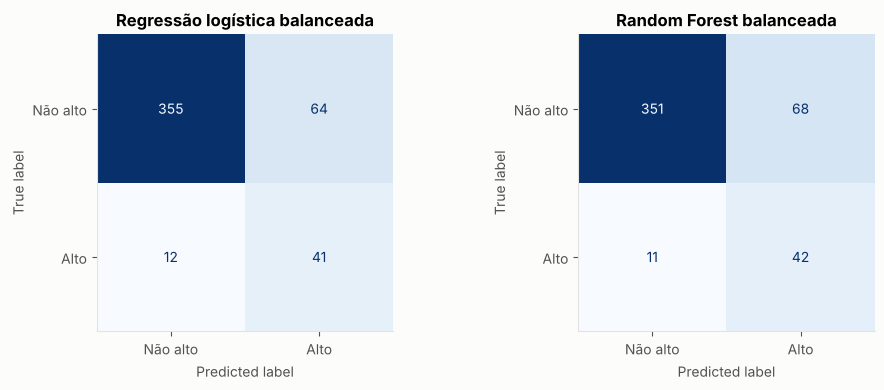

In [7]:
fig, eixos = plt.subplots(1, len(finais), figsize=(5 * len(finais), 4))
eixos = np.atleast_1d(eixos)
for ax, (nome, m) in zip(eixos, finais.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, m.predict(X_test), display_labels=['Não alto', 'Alto'], cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(nome); ax.grid(False)
fig.tight_layout(); plt.show()

## 6. Interpretação

Com as variáveis padronizadas, os coeficientes da regressão logística ficam comparáveis entre si. A importância por permutação confirma a leitura sem depender da forma do modelo.

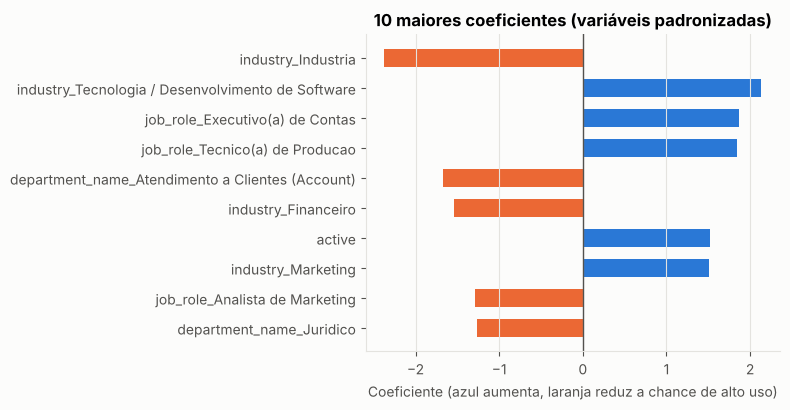

,variavel,queda_pr_auc
2,industry,0.2680
1,department_name,0.0847
5,active,0.0547
0,job_role,0.0260
3,company_size,0.0247
4,tenure_days,0.0085
6,seniority,-0.0057


In [8]:
lr = finais['Regressão logística balanceada']
nomes = [n.split('__')[-1] for n in lr.named_steps['pre'].get_feature_names_out()]
coef = pd.DataFrame({'caracteristica': nomes, 'coeficiente': lr.named_steps['clf'].coef_[0]})
coef['abs'] = coef.coeficiente.abs()
top = coef.sort_values('abs', ascending=False).head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(top.caracteristica, top.coeficiente, color=[AZUL if v > 0 else LARANJA for v in top.coeficiente], height=0.6)
ax.axvline(0, color=TINTA2, lw=1); ax.grid(axis='y', visible=False)
ax.set(title='10 maiores coeficientes (variáveis padronizadas)', xlabel='Coeficiente (azul aumenta, laranja reduz a chance de alto uso)')
fig.tight_layout(); plt.show()

imp = permutation_importance(finais[melhor], X_test, y_test, scoring='average_precision', n_repeats=10, random_state=SEED)
pd.DataFrame({'variavel': X.columns, 'queda_pr_auc': imp.importances_mean}).sort_values('queda_pr_auc', ascending=False).round(4)

## 7. Conclusões da versão corrigida

In [9]:
print(f"Melhor modelo na validação cruzada: {melhor} — PR-AUC {cv_tab.loc[melhor, 'pr_auc']:.3f}, ROC-AUC {cv_tab.loc[melhor, 'roc_auc']:.3f} ± {cv_tab.loc[melhor, 'roc_auc_dp']:.3f}")
print(f"No teste — {melhor}: PR-AUC {teste_tab.loc[melhor, 'pr_auc']:.3f}, recall {teste_tab.loc[melhor, 'recall']:.2f}, precisão {teste_tab.loc[melhor, 'precisao']:.2f}")
print(f"No teste — Regressão logística balanceada: PR-AUC {teste_tab.loc['Regressão logística balanceada', 'pr_auc']:.3f}, "
      f"recall {teste_tab.loc['Regressão logística balanceada', 'recall']:.2f}, precisão {teste_tab.loc['Regressão logística balanceada', 'precisao']:.2f}")

Melhor modelo na validação cruzada: Random Forest balanceada — PR-AUC 0.561, ROC-AUC 0.903 ± 0.022
No teste — Random Forest balanceada: PR-AUC 0.543, recall 0.79, precisão 0.38
No teste — Regressão logística balanceada: PR-AUC 0.532, recall 0.77, precisão 0.39
